In [591]:
import pandas as pd 
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from datetime import date, datetime
! pip install lxml_html_clean 
import dataframe_image as dfi
import os


# Background
#### Affirm is a financial technology company that offers consumers transparent, flexible payment options at the point of sale. When a consumer checks out at an Affirm merchant partner, they can choose from several lending products:

#### Split Pay (Pay-in-4): A short-term, interest-free product where the consumer pays in 4 biweekly installments. Affirm earns revenue through the merchant discount rate (MDR) only.
#### Interest-Bearing Installments: Longer-term loans (3–18 months) where the consumer pays interest (APR typically 10–36%). Affirm earns revenue from both MDR and consumer interest payments.
#### 0% APR Installments: Longer-term loans (3–18 months) at 0% interest, subsidized by the merchant paying a higher MDR. Affirm earns revenue through MDR only.

#### Affirm partners with merchants across diverse verticals: electronics, home furnishing, travel, healthcare, fashion, fitness, and auto parts. Each vertical has a different risk profile, average order value, and growth trajectory.

# The Business Question
## Affirm's leadership team is evaluating where to allocate capital for the next fiscal year. Specifically, they want to know:

### Which merchant verticals and product types should Affirm increase investment in, and which should it pull back from?


### Example of "investment" are:
### Expanding the credit box (loosening credit restrictions to approve more applicants in selected segments)
### Offering or expanding 0% APR promotional programs
### Driving more merchant acquisition
### Launching product and/or marketing initiatives

### Your task is to analyze the provided datasets, form a data-driven recommendation, and present it to Affirm's leadership panel.

# Where should affirm be allocating money into???

In [592]:
loans = pd.read_csv(f'./data/loans.csv')
merchants = pd.read_csv(f'./data/merchants.csv')
users = pd.read_csv(f'./data/users.csv')

In [593]:
# making all of these date times easier to acccess and able to parse and filter
loans['origination_date'] = pd.to_datetime(loans['origination_date'])
merchants['integration_date'] = pd.to_datetime(merchants['integration_date'])
users['signup_date'] = pd.to_datetime(users['signup_date'])
users['first_loan_date'] = pd.to_datetime(users['first_loan_date'])

In [594]:
def tell_me_about_the_data(df):
    
    print(f'Displaying some rows of the df  to be able to understand what we are looking at')
    display(df.head(2))
    print(f'----------------------------------------------------------------------')
    # print(f'This is some information about the df')
    # print(df.info())
    print(f'----------------------------------------------------------------------')
    print(f'This is some info on the shape of the frame, meaning the amount of rows and cols')
    print(f'Data has {df.shape[0]} rows and {df.shape[1]} columns')
    print(f'----------------------------------------------------------------------')
    duplicates = df.duplicated().sum()
    print(f'This is how many rows are duplicated {duplicates}')
    if duplicates > 0:
        print('Sample duplicate rows')  
        display(df[df.duplicated()].head())  
        
    missing_data = df.isna().sum()

    missing_filtered = {item: count for item, count in missing_data.items() if count > 0}    
    for item, count in missing_filtered.items():
        print(f'{item} col has a count of {count} missing entries')

        print(f'This is worth noting --  Investigate the missing rows.')
    
    print(f'----------------------------------------------------------------------')
    return f'Done Checking'

print(tell_me_about_the_data(loans))

print(tell_me_about_the_data(merchants))

print(tell_me_about_the_data(users))





Displaying some rows of the df  to be able to understand what we are looking at


,loan_id,user_id,merchant_id,origination_date,loan_amount,loan_term_months,product_type,apr,mdr,fico_score,is_new_to_affirm,loan_status,total_paid,mdr_fees,interest_collected,credit_loss,cost_of_funds_bps
0,L000986,U00549,M018,2025-10-25,307.85,3,installment_ib,0.2790,0.0501,559.0,False,current,212.39,15.42,7.16,0.0,350
1,L004406,U02481,M024,2024-09-06,2447.09,6,installment_ib,0.2385,0.0645,590.0,True,paid_off,2593.00,157.84,145.91,0.0,350


----------------------------------------------------------------------
----------------------------------------------------------------------
This is some info on the shape of the frame, meaning the amount of rows and cols
Data has 7294 rows and 17 columns
----------------------------------------------------------------------
This is how many rows are duplicated 0
fico_score col has a count of 492 missing entries
This is worth noting --  Investigate the missing rows.
----------------------------------------------------------------------
Done Checking
Displaying some rows of the df  to be able to understand what we are looking at


,merchant_id,merchant_name,vertical,avg_aov,has_promo_program,integration_date,avg_monthly_checkouts
0,M001,TechHaven,electronics,620,True,2023-02-16,4200
1,M002,CircuitEdge,electronics,480,False,2020-06-18,3100


----------------------------------------------------------------------
----------------------------------------------------------------------
This is some info on the shape of the frame, meaning the amount of rows and cols
Data has 25 rows and 7 columns
----------------------------------------------------------------------
This is how many rows are duplicated 0
----------------------------------------------------------------------
Done Checking
Displaying some rows of the df  to be able to understand what we are looking at


,user_id,signup_date,first_loan_date,total_loans,total_gmv,fico_at_first_loan,state,age_bucket
0,U00001,2024-08-01,2025-01-12,1,2632.25,530,OH,35-44
1,U00002,2023-07-24,2024-08-20,3,2786.70,647,SC,25-34


----------------------------------------------------------------------
----------------------------------------------------------------------
This is some info on the shape of the frame, meaning the amount of rows and cols
Data has 4000 rows and 8 columns
----------------------------------------------------------------------
This is how many rows are duplicated 0
----------------------------------------------------------------------
Done Checking


### okay, we checked for duplicates and nulls. Let us check for foreign and primary keys

In [595]:
loan_cols = loans.columns
merchant_cols = merchants.columns 
users_cols = users.columns

columns_in_common = [col for col in loan_cols if (col in merchant_cols) or (col in  users_cols)]

columns_in_common

# okay, so we can see that these are all interconnected.

id_for_loans = loan_cols[:3]

# merchants checks out - this is for mapping
merchants[['merchant_id', 'merchant_name']].nunique() 

entries = users.shape[0]

if int(users['user_id'].nunique()) ==  entries:
    print(f'there are all completely unique users')
    
    
    
vc = loans[id_for_loans].value_counts()
duplicate_counts = vc[vc > 1]

dupes = loans[loans.duplicated(subset=id_for_loans, keep=False)].sort_values(by = ['loan_id', 'user_id', 'merchant_id'], ascending = [True, True, True])

display(dupes.head(6))
# These are all dupes, and a lot of these numbers dont really make sense...

there are all completely unique users


,loan_id,user_id,merchant_id,origination_date,loan_amount,loan_term_months,product_type,apr,mdr,fico_score,is_new_to_affirm,loan_status,total_paid,mdr_fees,interest_collected,credit_loss,cost_of_funds_bps
540,L000090,U00052,M007,1925-06-15,3403.63,12,installment_ib,0.3074,0.0824,585.0,True,delinquent_30,2967.25,280.46,395.31,115.14,350
1928,L000090,U00052,M007,2024-11-21,3403.63,12,installment_ib,0.3074,0.0824,585.0,True,delinquent_30,2967.25,280.46,395.31,115.14,350
5215,L000091,U00052,M009,2031-08-24,933.11,12,installment_0pct,0.0000,0.0718,572.0,False,paid_off,933.11,67.00,0.00,0.00,250
6130,L000091,U00052,M009,2025-04-22,933.11,12,installment_0pct,0.0000,0.0718,572.0,False,paid_off,933.11,67.00,0.00,0.00,250
1488,L000144,U00083,M008,1924-06-16,2267.75,18,installment_ib,0.2462,0.0877,599.0,False,paid_off,2686.49,198.88,418.74,0.00,300
4454,L000144,U00083,M008,2025-04-16,2267.75,18,installment_ib,0.2462,0.0877,599.0,False,paid_off,2686.49,198.88,418.74,0.00,300


### okay, so the origination date is going to be the issue here. 
### It does not make sense they have loans from the future or past,
### unless they inherited loans from the past, which is also unlikely.

### we will filter based on affirms launch date and today's current data

In [596]:
july_start_date = pd.to_datetime('2024-07-01')

december = pd.to_datetime('2025-12-31')
# in theory, this should cut in half, so 160
dupes.shape[0]

mask = (dupes['origination_date'] >= july_start_date ) & (dupes['origination_date'] <= december)

# this worked !
# we can just apply a simple mask to the data to be able to retain the good data.
# we can bring all our dfs again
dupes[mask].shape[0]

160

In [597]:
# good
users 
# good
merchants
# fixing
mask_loans = (loans['origination_date'] >= july_start_date ) & (loans['origination_date'] <= december)
new_loans = loans[mask_loans]
# valid mask
loans.shape[0] - new_loans.shape[0]


160

In [598]:
new_loans_copy = new_loans.copy()

# print(tell_me_about_the_data(loans))

percent_of_rows_missing_for_loans_df = (492 / new_loans_copy.shape[0] * 100)
print(percent_of_rows_missing_for_loans_df)

# I am going to investigate this portion of the data missing nulls since 7% is a 
# good amount of data to just drop. 

percent_of_rows_missing_for_loans_df


# median credit score would be 
median_score = new_loans_copy[ ~new_loans_copy['fico_score'].isna()]['fico_score'].median()

new_loans_copy['fico_score'] = new_loans_copy['fico_score'].fillna('Missing')
new_loans_copy['fico_score'] = pd.to_numeric(new_loans_copy['fico_score'], errors='coerce')

# good
tell_me_about_the_data(new_loans_copy)

6.896551724137931
Displaying some rows of the df  to be able to understand what we are looking at


,loan_id,user_id,merchant_id,origination_date,loan_amount,loan_term_months,product_type,apr,mdr,fico_score,is_new_to_affirm,loan_status,total_paid,mdr_fees,interest_collected,credit_loss,cost_of_funds_bps
0,L000986,U00549,M018,2025-10-25,307.85,3,installment_ib,0.2790,0.0501,559.0,False,current,212.39,15.42,7.16,0.0,350
1,L004406,U02481,M024,2024-09-06,2447.09,6,installment_ib,0.2385,0.0645,590.0,True,paid_off,2593.00,157.84,145.91,0.0,350


----------------------------------------------------------------------
----------------------------------------------------------------------
This is some info on the shape of the frame, meaning the amount of rows and cols
Data has 7134 rows and 17 columns
----------------------------------------------------------------------
This is how many rows are duplicated 0
fico_score col has a count of 483 missing entries
This is worth noting --  Investigate the missing rows.
----------------------------------------------------------------------


'Done Checking'

In [599]:
display(new_loans_copy.head())
display(users)
display(merchants.head())


,loan_id,user_id,merchant_id,origination_date,loan_amount,loan_term_months,product_type,apr,mdr,fico_score,is_new_to_affirm,loan_status,total_paid,mdr_fees,interest_collected,credit_loss,cost_of_funds_bps
0,L000986,U00549,M018,2025-10-25,307.85,3,installment_ib,0.2790,0.0501,559.0,False,current,212.39,15.42,7.16,0.0,350
1,L004406,U02481,M024,2024-09-06,2447.09,6,installment_ib,0.2385,0.0645,590.0,True,paid_off,2593.00,157.84,145.91,0.0,350
2,L004180,U02351,M022,2024-12-22,1254.24,1,split_pay,0.0000,0.0510,659.0,True,paid_off,1254.24,63.97,0.00,0.0,300
3,L002407,U01342,M007,2024-11-04,2995.79,18,installment_ib,0.2311,0.0787,811.0,True,current,2733.92,235.77,403.86,0.0,450
4,L004019,U02257,M025,2025-05-06,129.88,1,split_pay,0.0000,0.0439,657.0,False,paid_off,129.88,5.70,0.00,0.0,300


,user_id,signup_date,first_loan_date,total_loans,total_gmv,fico_at_first_loan,state,age_bucket
0,U00001,2024-08-01,2025-01-12,1,2632.25,530,OH,35-44
1,U00002,2023-07-24,2024-08-20,3,2786.70,647,SC,25-34
2,U00003,2025-01-12,2025-04-24,1,864.46,751,UT,25-34
3,U00004,2024-08-03,2025-01-12,2,407.61,617,UT,18-24
4,U00005,2024-06-06,2025-06-01,1,847.58,608,GA,35-44
...,...,...,...,...,...,...,...,...
3995,U03996,2024-11-17,2025-10-09,1,439.44,632,CO,35-44
3996,U03997,2024-07-12,2024-08-29,2,359.27,651,AL,45-54
3997,U03998,2024-10-03,2025-04-21,2,1639.99,617,NJ,35-44
3998,U03999,2025-03-03,2025-09-15,1,1599.11,577,CA,45-54


,merchant_id,merchant_name,vertical,avg_aov,has_promo_program,integration_date,avg_monthly_checkouts
0,M001,TechHaven,electronics,620,True,2023-02-16,4200
1,M002,CircuitEdge,electronics,480,False,2020-06-18,3100
2,M003,PixelPeak,electronics,950,True,2023-08-15,1800
3,M004,NestCraft,home_furnishing,1100,True,2022-09-05,2600
4,M005,UrbanRoost,home_furnishing,780,True,2020-12-20,1900


In [600]:
# merging 

main_df = pd.merge(pd.merge(new_loans_copy,
                   users,
                   how = 'inner',
                   left_on = 'user_id',
                   right_on = 'user_id'), 
                   merchants, 
                   how = 'inner',
                   left_on = 'merchant_id',
                   right_on = 'merchant_id')

main_df.columns = main_df.columns.str.lower().str.replace(' ', '_')

main_df = main_df.sort_values(['loan_id', 'user_id', 'merchant_id'], ascending = [True, True, True]).reset_index(drop = True)

main_df.columns

keep = ['loan_id','user_id','merchant_id','vertical','product_type',
        'origination_date','loan_amount','loan_term_months','apr','mdr',
        'mdr_fees','interest_collected','credit_loss','cost_of_funds_bps',
        'loan_status','fico_score','is_new_to_affirm',
        'has_promo_program','avg_aov','age_bucket','state']


main_df = main_df[keep]

main_df['cost_of_funds_dollars'] = main_df['loan_amount'] * (main_df['cost_of_funds_bps'] / 10000)

main_df['net_revenue'] =  (main_df['mdr_fees']              # revenue: merchant fee
    + main_df['interest_collected']    # revenue: consumer interest
    - main_df['credit_loss']           # cost: defaults
    - main_df['cost_of_funds_dollars']         # cost: borrowing the money to lend
    )

main_df['gross_revenue'] = (main_df['mdr_fees']              # revenue: merchant fee
    + main_df['interest_collected'])

main_df['gross_cost'] =     (main_df['credit_loss']         
    + main_df['cost_of_funds_dollars']         
    )

# interested in seeihg mdr fee as well, to be fair 



In [601]:
main_df[['credit_loss', 'cost_of_funds_dollars']]


,credit_loss,cost_of_funds_dollars
0,795.56,78.96750
1,0.00,24.56700
2,0.00,51.06605
3,0.00,20.35080
4,0.00,30.25610
...,...,...
7129,0.00,40.18480
7130,0.00,25.41480
7131,0.00,39.97775
7132,0.00,7.92715


In [602]:
base_segment_product = main_df.groupby(['vertical', 'product_type']).apply(lambda x : pd.Series({
    'gmv ($k)' : (x['loan_amount'].sum() / 1e3).round(0) ,
    'net_revenue($k)' : (x['net_revenue'].sum() / 1e3).round(0),
    'net_revenue_margin' : ((x['net_revenue'].sum() /
                            x['loan_amount'].sum()) * 100).round(2),
    'loss_amount ($k)' : (x['credit_loss'].sum() / 1e3).round(0) ,
    'loss_rate' : ((x['credit_loss'].sum() / 
                x['loan_amount'].sum()) * 100).round(2)
    
    }),
    include_groups = False
    ).reset_index()





risky_portfolio = base_segment_product.sort_values(by = ['gmv ($k)', 'loss_amount ($k)', 'loss_rate'], ascending = [False, False, False]).reset_index(drop  = True)
    
lr_mean = base_segment_product['loss_rate'].mean()
lr_median = base_segment_product['loss_rate'].median()

print(lr_mean)
print(lr_median)
weighted_avg_loss_rate = (base_segment_product['loss_rate'] * base_segment_product['gmv ($k)']).sum() / base_segment_product['gmv ($k)'].sum()
print(weighted_avg_loss_rate)
# bps difference
print((risky_portfolio.iloc[0,-1] - lr_mean) * 100)
# bps difference
print((risky_portfolio.iloc[0,-1] - lr_median) * 100)

# display(risky_portfolio)


# okay, so we are seeing aroung a 250 - 262 spike in bps from the travel airline across all segments, with auto_parts in the split pay segment also playing a factor. 


risky_portfolios = risky_portfolio.sort_values(by = ['loss_rate'], ascending = False).iloc[:5]

# Looking, travel has the best net margin, by a mile, which is nice to see, we can also see that 

# let us look at the fee as well. 


1.6471428571428572
1.52
2.018802621628435
252.28571428571428
265.0


In [603]:

included_fees_and_outlook = main_df.groupby(['vertical', 'product_type']).apply(lambda x : pd.Series({
    'gmv ($k)' : (x['loan_amount'].sum() / 1e3) ,
    # alone by itself should tie
    'net_revenue($k)' : (x['net_revenue'].sum() / 1e3),

    # gross amount should tie.
    'gross_revenue($k)' : (x['gross_revenue'].sum() / 1e3),
    'gross_cost($k)' : (x['gross_cost'].sum() / 1e3),

    # revenue drivers
    'interest collected ($k)' : (x['interest_collected'].sum()  / 1e3) ,
    'mdr fees ($k)' : (x['mdr_fees'].sum()  / 1e3) ,
    # how much money we are making based on amt of loans
    'net_revenue_margin' : ((x['net_revenue'].sum() /
                            x['loan_amount'].sum()) * 100),

    # money losing, bad money
    'loss_amount ($k)' : (x['credit_loss'].sum() / 1e3) ,

    # cost to borrow money, not a apart of loss amount
    'cost to borrow ($k)' : (x['cost_of_funds_dollars'].sum() / 1e3) ,     

    'loss_rate' : ((x['credit_loss'].sum() / 
                x['loan_amount'].sum()) * 100).round(2),

    # interested in seeing the merchant avg
    'merchant_fee_as_a_%' : (x['mdr'].mean() * 100).round(2),
    'merchant_fee_as_a_%_weighted' : ((x['mdr_fees'].sum() / x['loan_amount'].sum()) * 100).round(2)

    
    }),
    include_groups = False
    ).assign(numbers_tie = lambda x: np.isclose(
    x['interest collected ($k)'] + x['mdr fees ($k)']
        - x['loss_amount ($k)'] - x['cost to borrow ($k)'],   
    x['net_revenue($k)'],                                      
    atol=1.0                                               
)).assign(clearing_margin = lambda x : x['net_revenue_margin'] - x['loss_rate'],
          variance_of_margin = lambda x: x['net_revenue_margin'] / x['loss_rate'] -1 ).reset_index()

included_fees_and_outlook = included_fees_and_outlook.sort_values(by = ['gmv ($k)', 'loss_amount ($k)', 'loss_rate'], ascending = [False, False, False]).reset_index(drop  = True)

os.makedirs('df_images', exist_ok= True)

dfi.export(
    included_fees_and_outlook, 
    'df_images/vertical_product_type_breakdown.png',
    table_conversion='matplotlib'
)

display(included_fees_and_outlook)


# interesting. travel install_ib dominate with mdr and interest collected, with it pretty even, 
# interest bearing accounts, undrstanadbly is the most profitable and direction. with higher gmv accounts, we can see
# that product types with interest bearing trickles to attractive margins.

# we can see there are two different stories with the highest net_margins. 
# healthcare has the highest margin, making for a great investment across a low 1.7 of risk rate 
# travel looks like attractive, on paper, but it is solely relying on the interest from these installment payments to incure a advantageous margin against 
# the loss rate. 

# it would be interesting to investigate the credit for these porfolios since travel for installment interestbearing porfolios seem volatile.
# mdr only propducts, where there is split pay 

included_fees_and_outlook['net_revenue_margin'] - included_fees_and_outlook['loss_rate']


,vertical,product_type,gmv ($k),net_revenue($k),gross_revenue($k),gross_cost($k),interest collected ($k),mdr fees ($k),net_revenue_margin,loss_amount ($k),cost to borrow ($k),loss_rate,merchant_fee_as_a_%,merchant_fee_as_a_%_weighted,numbers_tie,clearing_margin,variance_of_margin
0,travel,installment_ib,547.63352,45.506242,87.00802,41.501778,43.17660,43.83142,8.309616,22.83530,18.666478,4.17,8.00,8.00,True,4.139616,0.992714
1,electronics,installment_ib,452.99964,32.748577,54.56428,21.815703,31.95051,22.61377,7.229272,6.24602,15.569683,1.38,4.98,4.99,True,5.849272,4.238603
2,healthcare,installment_ib,404.05499,38.668971,59.11332,20.444349,30.71817,28.39515,9.570225,6.93090,13.513449,1.72,7.02,7.03,True,7.850225,4.564084
3,fashion,split_pay,398.82987,-7.982014,16.04394,24.025954,0.00000,16.04394,-2.001358,10.55750,13.468454,2.65,4.02,4.02,True,-4.651358,-1.755230
4,fashion,installment_ib,304.41478,16.298650,33.39130,17.092650,21.14794,12.24336,5.354093,6.79461,10.298040,2.23,4.02,4.02,True,3.124093,1.400938
5,home_furnishing,installment_ib,287.42184,23.583237,38.46460,14.881362,21.16206,17.30254,8.205096,5.23125,9.650112,1.82,6.00,6.02,True,6.385096,3.508294
6,travel,installment_0pct,174.46370,4.320507,12.84023,8.519723,0.00000,12.84023,2.476450,2.77109,5.748633,1.59,7.39,7.36,True,0.886450,0.557516
7,electronics,installment_0pct,171.38224,-0.496489,7.29240,7.788888,0.00000,7.29240,-0.289697,1.93553,5.853359,1.13,4.24,4.26,True,-1.419697,-1.256369
8,electronics,split_pay,155.16849,-0.513670,7.75521,8.268880,0.00000,7.75521,-0.331040,2.99554,5.273340,1.93,4.98,5.00,True,-2.261040,-1.171524
9,home_furnishing,installment_0pct,150.39212,2.530398,7.93819,5.407792,0.00000,7.93819,1.682534,0.21927,5.188522,0.15,5.27,5.28,True,1.532534,10.216893


0     4.139616
1     5.849272
2     7.850225
3    -4.651358
4     3.124093
5     6.385096
6     0.886450
7    -1.419697
8    -2.261040
9     1.532534
10    6.848624
11    6.649232
12    0.919093
13   -4.822733
14    0.543566
15    0.157550
16    0.388460
17   -0.417503
18   -0.539417
19    1.232925
20   -3.699003
dtype: float64

In [604]:
main_df['co_gmv'] = main_df['loan_amount'].where(main_df['loan_status']=='charged_off', 0)

# display(main_df[['loan_amount', 'co_gmv']])

seg_check = main_df.groupby(['vertical','product_type']).apply(lambda g: pd.Series({
    # amt of money lost in the segment and product type
    'loss_rate':       100*g['credit_loss'].sum()/g['loan_amount'].sum(),
    # amount of actuall charged-off gmv money v loan amount. what loan money really went bad
    'chargeoff_gmv_%': 100*g['co_gmv'].sum()/g['loan_amount'].sum(),
    # the amount of accounts that are charged-offs as a whole
    'chargeoff_cnt_%': 100*(g['loan_status']=='charged_off').mean(),
}), include_groups=False)


# curious to look at the charge-off counts
co_outlook = seg_check.sort_values(by = ['loss_rate', 'chargeoff_gmv_%', 'chargeoff_cnt_%'], ascending= [False, False, False])


# os.makedir
# dfi.export(co_outlook, '')

dfi.export(
    co_outlook, 
    'df_images/co_accounts_outlook.png',
    table_conversion='matplotlib'
)

# display(included_fees_and_outlook)

included_fees_and_outlook[included_fees_and_outlook['product_type'] == 'installment_ib']
included_fees_and_outlook[included_fees_and_outlook['product_type'] != 'installment_ib'].sort_values(by = ['clearing_margin'], ascending = True)

,vertical,product_type,gmv ($k),net_revenue($k),gross_revenue($k),gross_cost($k),interest collected ($k),mdr fees ($k),net_revenue_margin,loss_amount ($k),cost to borrow ($k),loss_rate,merchant_fee_as_a_%,merchant_fee_as_a_%_weighted,numbers_tie,clearing_margin,variance_of_margin
13,auto_parts,split_pay,108.64971,-1.730500,5.42587,7.156370,0.0,5.42587,-1.592733,3.50822,3.648150,3.23,4.99,4.99,True,-4.822733,-1.493106
3,fashion,split_pay,398.82987,-7.982014,16.04394,24.025954,0.0,16.04394,-2.001358,10.55750,13.468454,2.65,4.02,4.02,True,-4.651358,-1.755230
20,fashion,installment_0pct,19.25002,-0.359783,0.64429,1.004073,0.0,0.64429,-1.869003,0.35160,0.652473,1.83,3.32,3.35,True,-3.699003,-2.021313
8,electronics,split_pay,155.16849,-0.513670,7.75521,8.268880,0.0,7.75521,-0.331040,2.99554,5.273340,1.93,4.98,5.00,True,-2.261040,-1.171524
7,electronics,installment_0pct,171.38224,-0.496489,7.29240,7.788888,0.0,7.29240,-0.289697,1.93553,5.853359,1.13,4.24,4.26,True,-1.419697,-1.256369
18,fitness,installment_0pct,39.17229,0.278352,2.03641,1.758058,0.0,2.03641,0.710583,0.48839,1.269668,1.25,5.08,5.20,True,-0.539417,-0.431533
17,travel,split_pay,54.93350,1.149482,4.44726,3.297778,0.0,4.44726,2.092497,1.37962,1.918158,2.51,8.05,8.10,True,-0.417503,-0.166336
15,fitness,split_pay,78.14956,0.920250,4.34435,3.424100,0.0,4.34435,1.177550,0.79930,2.624800,1.02,5.53,5.56,True,0.157550,0.154461
16,healthcare,split_pay,61.37978,1.171409,4.29444,3.123031,0.0,4.29444,1.908460,0.93336,2.189671,1.52,7.05,7.00,True,0.388460,0.255566
14,home_furnishing,split_pay,101.65609,1.579295,6.03801,4.458715,0.0,6.03801,1.553566,1.02692,3.431795,1.01,5.93,5.94,True,0.543566,0.538185


In [605]:
# im curiosu about the fico bands now


bins =  [300, 580, 620, 660, 700, 740, 850]
labels = ['<580', '580-619', '620-659', '660-699', '700-739', '740+']
main_df['fico_band'] = pd.cut(main_df['fico_score'], bins=bins, labels=labels, right=False)

segmentation_story = main_df.groupby(['vertical','fico_band'], observed=True).apply(
    lambda x: pd.Series({
        # need to have a valid amount of loans to be able judge fairly
    
        'num_loans' : len(x) ,
        'gmv amt' : x['loan_amount'].sum(),
        'loss_amount' : x['credit_loss'].sum(),
        'loss_rate': round(100*x['credit_loss'].sum()/x['loan_amount'].sum(), 2), 
        'net_revenue_margin' : ((x['net_revenue'].sum() /

                            x['loan_amount'].sum()) * 100).round(2)
        
    }), include_groups=False)

segmentation_story['loss_rate_shown'] = segmentation_story['loss_rate'].where(segmentation_story['num_loans'] >= 30, None)

fico_story = main_df.groupby(['fico_band']).apply(lambda x : pd.Series({'loss_rate' : ((x['credit_loss'].sum() / 
                x['loan_amount'].sum()) * 100).round(2)
                } 
                ), include_groups = False)

fico_story = fico_story.sort_values(by = 'loss_rate', ascending= False)

segmentation_story.sort_values(by = 'loss_rate', ascending=False)

# matrix

# loss matrix
loss_grid = segmentation_story['loss_rate_shown'].reset_index().pivot(index = 'vertical', values = 'loss_rate_shown', columns = 'fico_band')

# number_of_loans matrix 
num_grid = segmentation_story['num_loans'].reset_index().pivot(index = 'vertical', values = 'num_loans', columns = 'fico_band')

# net revenue margin matrix
revenue_margin_grid = segmentation_story['net_revenue_margin'].reset_index().pivot(index = 'vertical', values = 'net_revenue_margin', columns = 'fico_band')

loss_mx = loss_grid[labels]
num_mx = num_grid[labels]
nr_margin_mx = revenue_margin_grid[labels]


C:\Users\jabob\AppData\Local\Temp\ipykernel_74656\2463025419.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fico_story = main_df.groupby(['fico_band']).apply(lambda x : pd.Series({'loss_rate' : ((x['credit_loss'].sum() /


In [606]:
# travel_story 

# important for restrategy for travel segment
tib = main_df[(main_df['vertical']=='travel') &
              (main_df['product_type']=='installment_ib')]


mask = tib['fico_score'] < 660
new_mask = tib['fico_score'] >= 660
lr_660 = tib[mask]['credit_loss'].sum() / tib[mask]['loan_amount'].sum()* 100 

lr_not_660 = tib[new_mask]['credit_loss'].sum() / tib[new_mask]['loan_amount'].sum()* 100 

print(lr_660, lr_not_660)

# print((lr_660 / lr_not_660 - 1) * 100 )
print((lr_660 - lr_not_660) * 100 )


band_loss = (tib.groupby('fico_band', observed=True)['credit_loss']
             .sum().sort_index())  



cum_share = band_loss.cumsum() / band_loss.sum() * 100  # as a rolling basis to understand.
print(cum_share.round(1))

6.380830974837803 1.5268495649448721
485.3981409892931
fico_band
<580        37.7
580-619     62.9
620-659     81.8
660-699     91.1
700-739     97.5
740+       100.0
Name: credit_loss, dtype: float64


In [607]:
super_high_lr = loss_mx.iloc[-1,:3]
lower_lr_rate = loss_mx.iloc[-1,3:]

print(f'Average of {super_high_lr.mean().round(1)} highest lr rates ')
print(f'Average of {lower_lr_rate.mean().round(1)} highest lr rates ')
print(super_high_lr.mean() / lower_lr_rate.mean() -1 )

loss_mx.iloc[-1,:3]

Average of 5.6 highest lr rates 
Average of 1.2 highest lr rates 
3.6022099447513813


fico_band
<580       7.64
580-619    5.29
620-659    3.73
Name: travel, dtype: float64

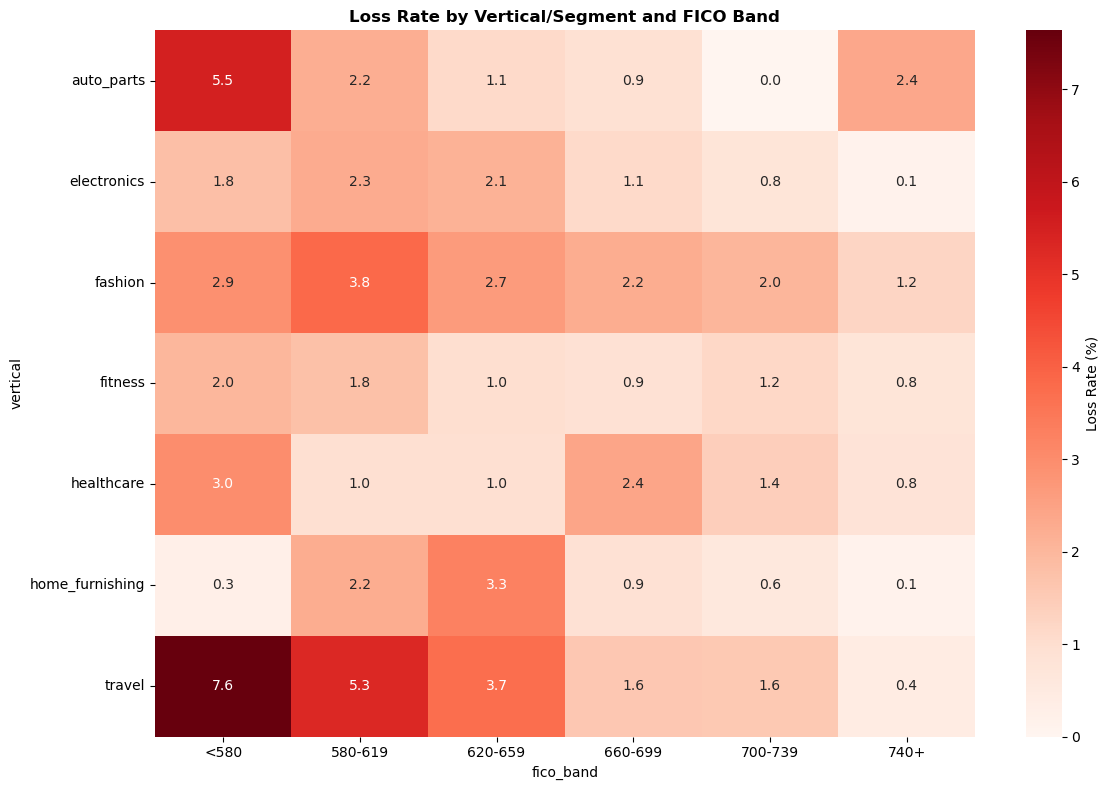

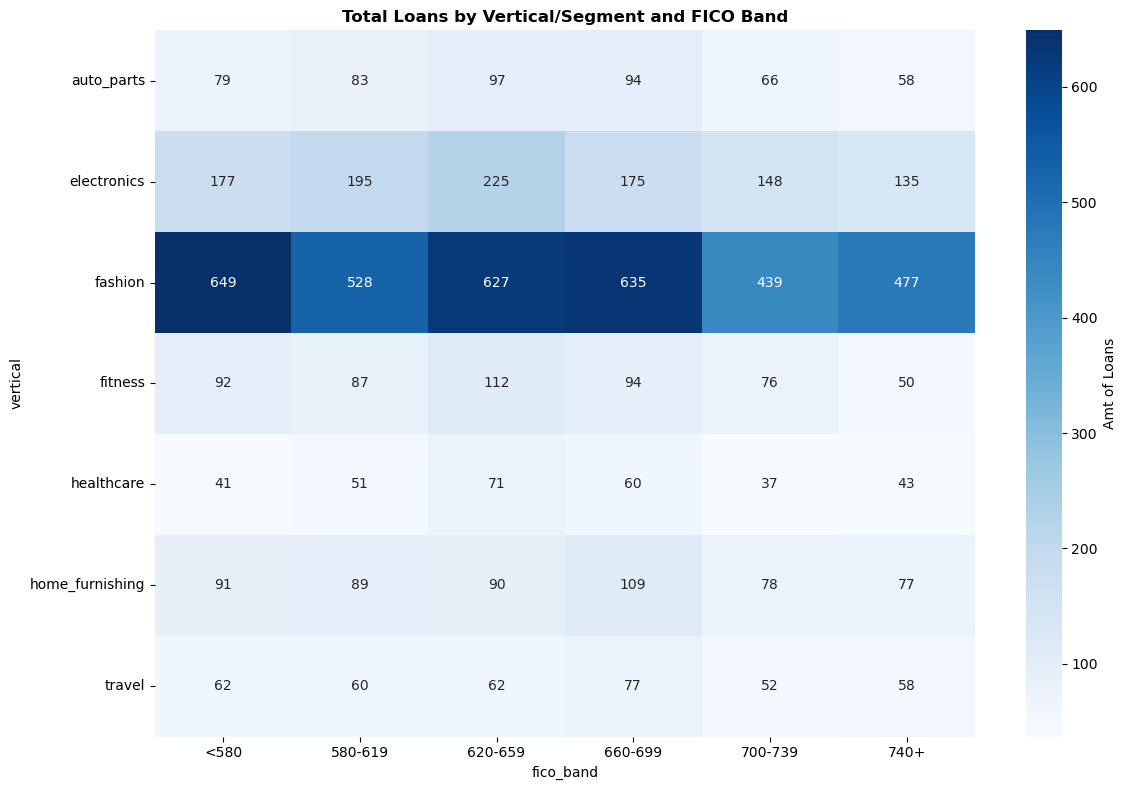

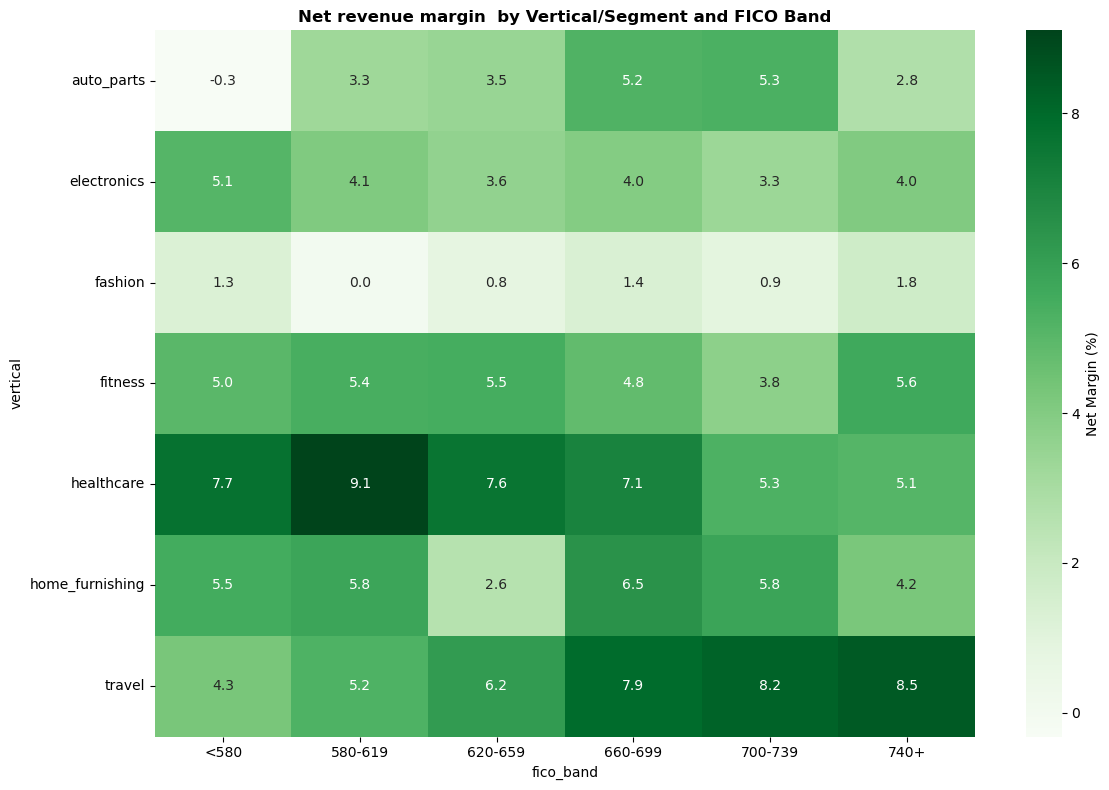

In [608]:
import seaborn as sns
import os

os.makedirs('graphs', exist_ok=True)

fig, ax  = plt.subplots(figsize = (12,8))
sns.heatmap(loss_mx, annot = True, fmt = '.1f', cmap= 'Reds' , cbar_kws = {'label' : 'Loss Rate (%)'})
ax.set_title('Loss Rate by Vertical/Segment and FICO Band', weight = 'bold')

plt.tight_layout()
plt.savefig(f'graphs/net_charge_off_mx.png')

plt.show()

fig, ax  = plt.subplots(figsize = (12,8))
sns.heatmap(num_mx, annot = True, fmt = '.0f', cmap= 'Blues' , cbar_kws = {'label' : 'Amt of Loans'})
ax.set_title('Total Loans by Vertical/Segment and FICO Band', weight = 'bold')

plt.tight_layout()
plt.savefig(f'graphs/num_loans_mx.png')

plt.show()


fig, ax  = plt.subplots(figsize = (12,8))
sns.heatmap(nr_margin_mx, annot = True, fmt = '.1f', cmap= 'Greens' , cbar_kws = {'label' : 'Net Margin (%)'})
ax.set_title('Net revenue margin  by Vertical/Segment and FICO Band', weight = 'bold')

plt.tight_layout()
plt.savefig(f'graphs/Net_revenue_margin_mx.png')
plt.show()




1.52
2.018802621628435
1.6471428571428572


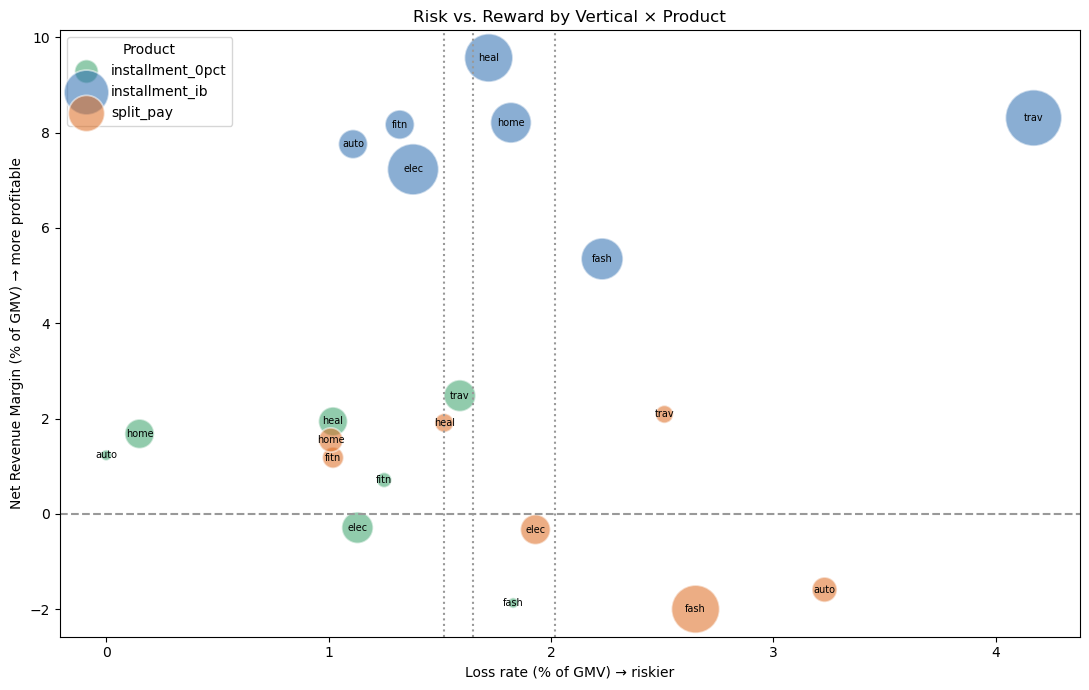

In [609]:
COL = {'installment_ib':'#2b6cb0', 'split_pay':'#dd6b20', 'installment_0pct':'#38a169'}


fig, ax = plt.subplots(figsize=(11,7))
for product, group in base_segment_product.groupby('product_type'):
    ax.scatter(group['loss_rate'], group['net_revenue_margin'],   
               s=group['gmv ($k)'] * 3,                            
               alpha=0.55, color=COL[product],
               edgecolors='white', linewidth=1.3, label=product)

for _, r in base_segment_product.iterrows():
    ax.annotate(r['vertical'][:4], (r['loss_rate'], r['net_revenue_margin']),
                fontsize=7, ha='center', va='center')


ax.axhline(0, color='#999', ls='--')                          

ax.axvline(base_segment_product['loss_rate'].median(), color='#999', ls=':')  
print(base_segment_product['loss_rate'].median())
ax.axvline(weighted_avg_loss_rate, color='#999', ls=':')  
print(weighted_avg_loss_rate) 

ax.axvline(lr_mean, color='#999', ls=':')  
print(lr_mean) 


ax.set_xlabel('Loss rate (% of GMV) → riskier')
ax.set_ylabel('Net Revenue Margin (% of GMV) → more profitable')
ax.set_title('Risk vs. Reward by Vertical × Product')
ax.legend(title='Product')
plt.tight_layout()
plt.savefig(f'graphs/risk_V_reward.png')
plt.show()

In [610]:
# can we include some time of time origin too to be able to understand the timeframe


# we know the last day was 12/31/2025

# all of these loans are still in the system, so we can technically still process the data

main_df['age_of_loan_in_days'] = (pd.to_datetime('2025-12-31') - main_df['origination_date']).dt.days

main_df['quarter'] = main_df['origination_date'].dt.to_period('Q').dt.strftime('%Y Q%q').apply(lambda x : f"{x[-2:]}'{x[2:4]}")


quarterly_impact = main_df.groupby('quarter').apply(lambda x : pd.Series({
    'loss_rate' : ((x['credit_loss'].sum() / x['loan_amount'].sum()) * 100).round(2),
    'average_loan_age_in_days' : x['age_of_loan_in_days'].mean().round(2)
}), include_groups = False).sort_index()

quarterly_impact

quarterly_impact_across_verticals = main_df.groupby(['quarter', 'vertical']).apply(lambda x : pd.Series({
    'loss_rate' : ((x['credit_loss'].sum() / x['loan_amount'].sum()) * 100).round(2),
    'average_loan_age_in_days' : x['age_of_loan_in_days'].mean().round(0)
}), include_groups = False).sort_index().reset_index()

loss_by_segment_over_time = quarterly_impact_across_verticals.pivot(values = 'loss_rate', 
                                        index = 'quarter',
                                        columns = 'vertical' )

age_by_segment_over_time = quarterly_impact_across_verticals.pivot(values = 'average_loan_age_in_days', 
                                        index = 'quarter',
                                        columns = 'vertical' )

order = ['Q3\'24','Q4\'24','Q1\'25','Q2\'25','Q3\'25','Q4\'25']
loss_by_segment_over_time = loss_by_segment_over_time.reindex(order)

loss_by_segment_over_time

vertical,auto_parts,electronics,fashion,fitness,healthcare,home_furnishing,travel
quarter,,,,,,,
Q3'24,0.55,1.92,1.63,0.20,0.64,1.62,1.96
Q4'24,1.57,1.72,5.04,2.91,3.11,0.70,4.64
Q1'25,2.04,1.26,2.94,0.15,0.07,2.54,4.36
Q2'25,2.53,1.55,2.83,1.50,4.80,0.90,2.91
Q3'25,1.79,2.08,1.39,0.87,1.22,1.50,3.40
Q4'25,2.66,0.32,1.41,1.25,0.00,0.51,3.20


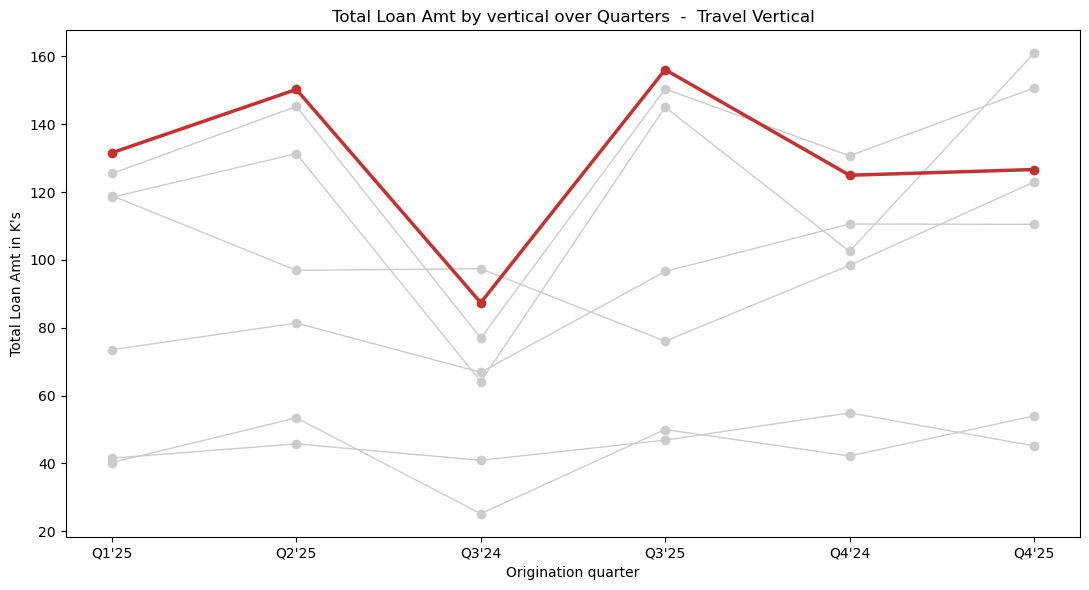

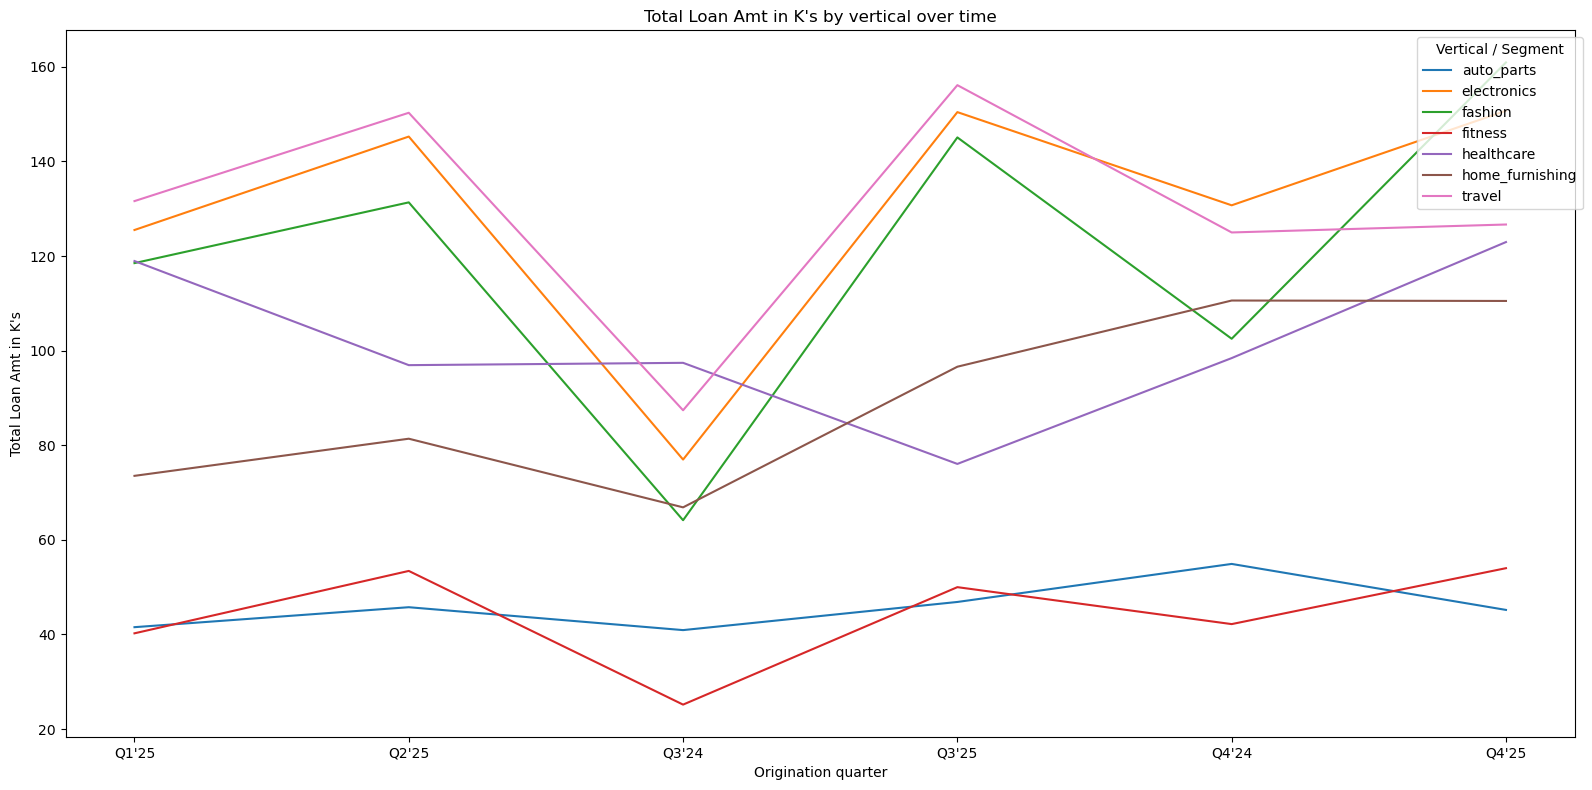

In [611]:
quarterly_impact_across_verticals_w_loans = main_df.groupby(['quarter', 'vertical']).apply(lambda x : pd.Series({
    'loss_rate' : ((x['credit_loss'].sum() / x['loan_amount'].sum()) * 100).round(2),
    'loss_amt' : (x['credit_loss'].sum()),
    'loan_cnt' : (len(x)),
    'total_gmv' : (x['loan_amount'].sum() / 1e3).round(2),
    'average_loan_age_in_days' : x['age_of_loan_in_days'].mean().round(0)
}), include_groups = False).sort_index().reset_index()

new_view_pivot_table = quarterly_impact_across_verticals_w_loans.pivot(values = 'total_gmv', 
                                        index = 'quarter',
                                        columns = 'vertical' )

new_view_pivot_table

fig, ax = plt.subplots(figsize=(11,6))
for v in new_view_pivot_table.columns:
    if v == 'travel':
        ax.plot(new_view_pivot_table.index, new_view_pivot_table[v], marker='o', lw=2.5, color='#c53030', label='Travel', zorder=5)
        ax.set_title('Total Loan Amt by vertical over Quarters  -  Travel Vertical')
        ax.set_xlabel(f'Origination quarter')
        ax.set_ylabel(f"Total Loan Amt in K's")
    else:
        ax.plot(new_view_pivot_table.index, new_view_pivot_table[v], marker='o', lw=1, color='#ccc', label='_nolegend_')

plt.tight_layout()
plt.savefig(f'graphs/Travel_total_loan_amt_over_time.png')
plt.show()




ax = new_view_pivot_table.plot(kind='line', figsize=(16,8))
ax.set_ylabel("Total Loan Amt in K's")
ax.set_xlabel('Origination quarter')
ax.set_title("Total Loan Amt in K's by vertical over time")
ax.legend(title='Vertical / Segment', bbox_to_anchor=(1.01,1), loc='upper right')
plt.tight_layout()
plt.savefig(f"graphs/Total Loan Amt in K's for segments over time.png")
plt.show()

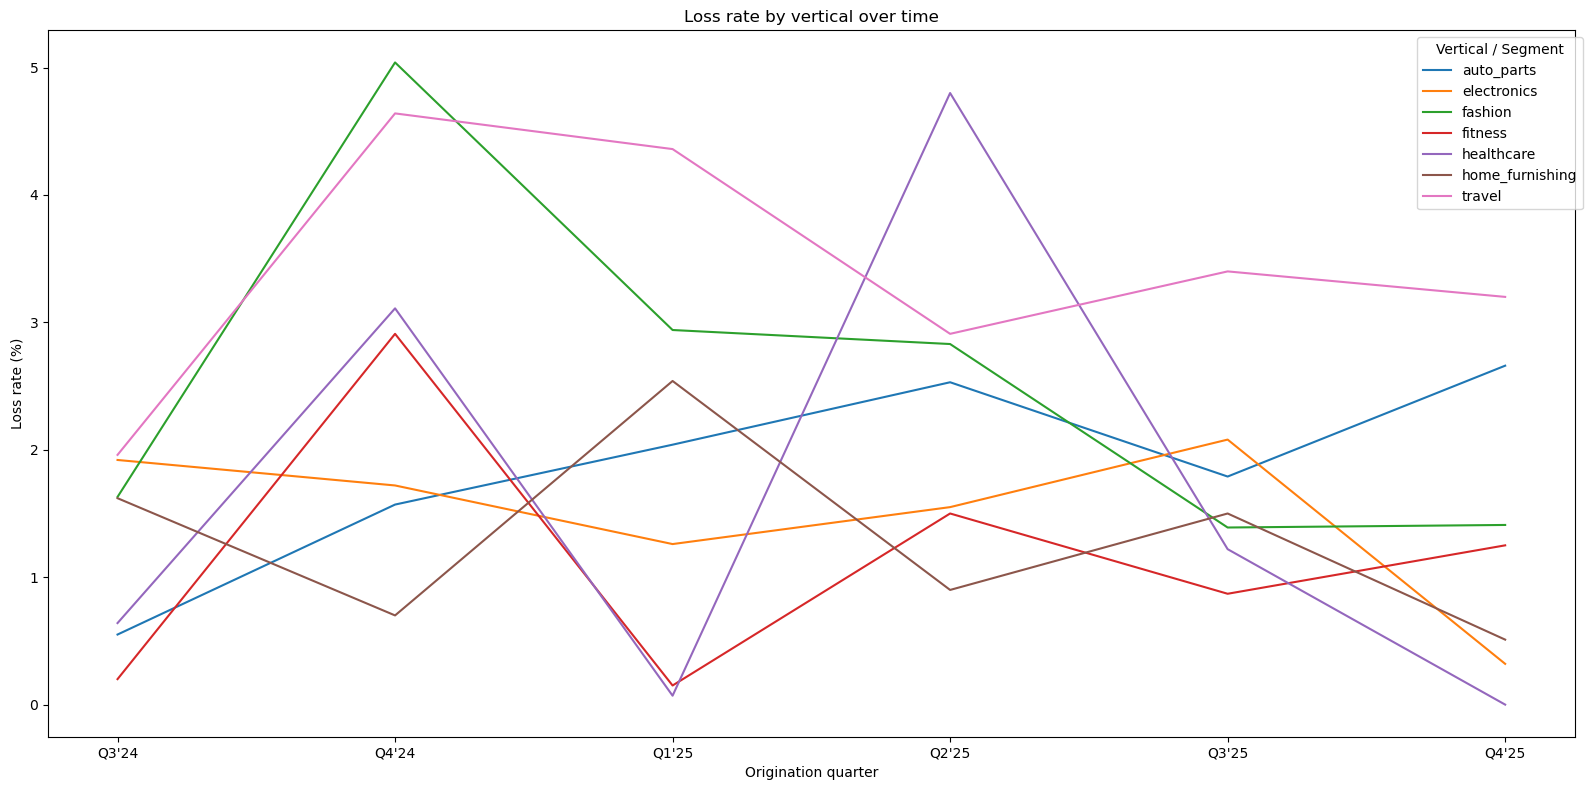

In [612]:
ax = loss_by_segment_over_time.plot(kind='line', figsize=(16,8))
ax.set_ylabel('Loss rate (%)')
ax.set_xlabel('Origination quarter')
ax.set_title('Loss rate by vertical over time')
ax.legend(title='Vertical / Segment', bbox_to_anchor=(1.01,1), loc='upper right')
plt.tight_layout()
plt.savefig(f'graphs/Loss rates for segments over time.png')
plt.show()

In [613]:
display(loss_by_segment_over_time)

mean_stats = loss_by_segment_over_time.describe().loc['mean']


print(mean_stats)
mean_across_all_segments = mean_stats.mean()

mean_across_all_segments


vertical,auto_parts,electronics,fashion,fitness,healthcare,home_furnishing,travel
quarter,,,,,,,
Q3'24,0.55,1.92,1.63,0.20,0.64,1.62,1.96
Q4'24,1.57,1.72,5.04,2.91,3.11,0.70,4.64
Q1'25,2.04,1.26,2.94,0.15,0.07,2.54,4.36
Q2'25,2.53,1.55,2.83,1.50,4.80,0.90,2.91
Q3'25,1.79,2.08,1.39,0.87,1.22,1.50,3.40
Q4'25,2.66,0.32,1.41,1.25,0.00,0.51,3.20


vertical
auto_parts         1.856667
electronics        1.475000
fashion            2.540000
fitness            1.146667
healthcare         1.640000
home_furnishing    1.295000
travel             3.411667
Name: mean, dtype: float64


1.9092857142857143

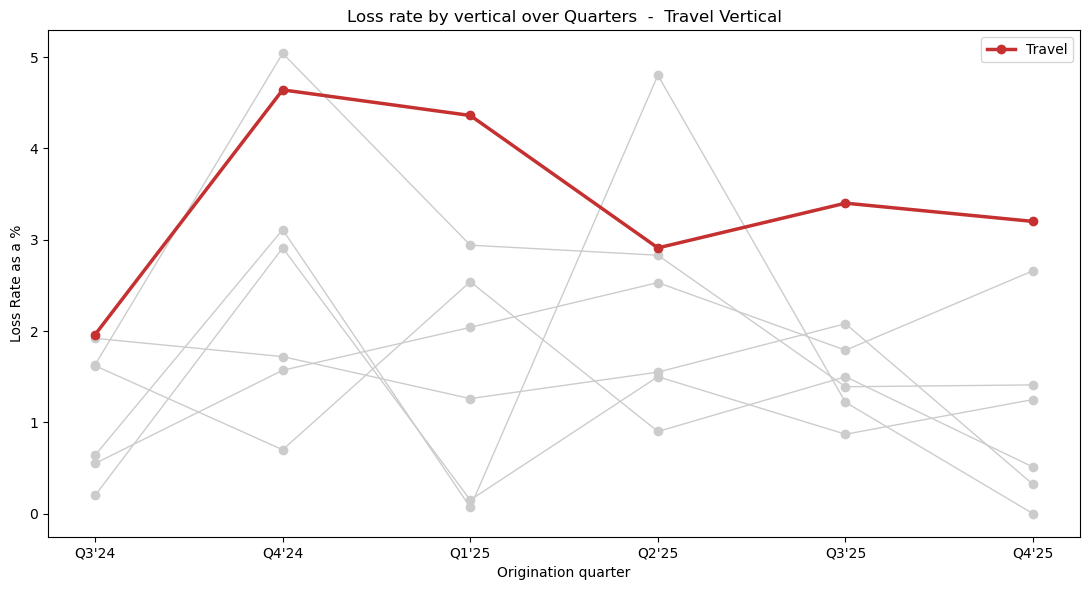

In [614]:

## really call out travel since this is the culprit.

fig, ax = plt.subplots(figsize=(11,6))
for v in loss_by_segment_over_time.columns:
    if v == 'travel':
        ax.plot(loss_by_segment_over_time.index, loss_by_segment_over_time[v], marker='o', lw=2.5, color='#c53030', label='Travel', zorder=5)
        ax.set_title('Loss rate by vertical over Quarters  -  Travel Vertical')
        ax.set_xlabel(f'Origination quarter')
        ax.set_ylabel(f'Loss Rate as a %')
    else:
        ax.plot(loss_by_segment_over_time.index, loss_by_segment_over_time[v], marker='o', lw=1, color='#ccc', label='_nolegend_')

plt.tight_layout()
plt.legend()
plt.savefig(f'graphs/Travel_risk_rate_over_origination_timeline.png')
plt.show()

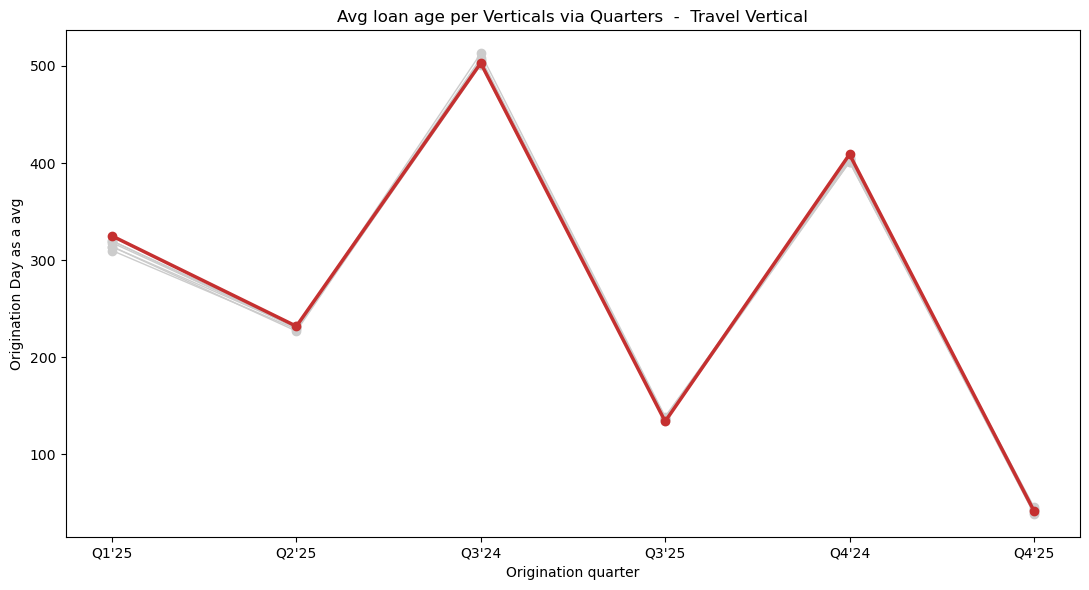

In [615]:
fig, ax = plt.subplots(figsize=(11,6))
for v in age_by_segment_over_time.columns:
    if v == 'travel':
        ax.plot(age_by_segment_over_time.index, age_by_segment_over_time[v], marker='o', lw=2.5, color='#c53030', label='Travel', zorder=5)
        ax.set_title('Avg loan age per Verticals via Quarters  -  Travel Vertical')
        ax.set_xlabel(f'Origination quarter')
        ax.set_ylabel(f'Origination Day as a avg')
    else:
        ax.plot(age_by_segment_over_time.index, age_by_segment_over_time[v], marker='o', lw=1, color='#ccc', label='_nolegend_')

plt.tight_layout()
plt.savefig(f'graphs/Travel_age_average_across_other_segments.png')
plt.show()

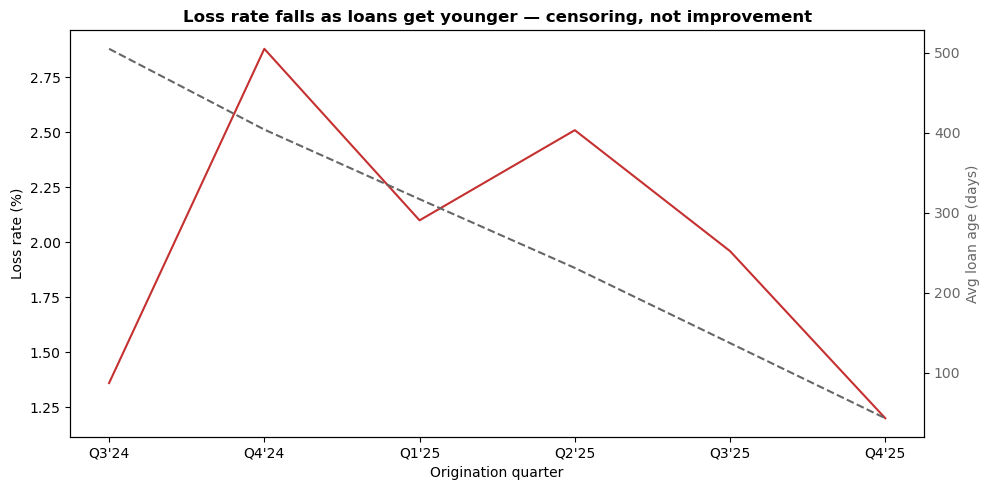

In [616]:
q_check = main_df.groupby(['quarter']).apply(lambda x : pd.Series({
    'loss_rate' : ((x['credit_loss'].sum() / x['loan_amount'].sum()) * 100).round(2),
    'average_loan_age_in_days' : x['age_of_loan_in_days'].mean().round(0)
}), include_groups = False).sort_index()

order = ['Q3\'24','Q4\'24','Q1\'25','Q2\'25','Q3\'25','Q4\'25']
q_check = q_check.reindex(order)

q = q_check  

fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(q.index, q['loss_rate'], color='#c53030', label='Loss rate')
ax1.set_ylabel('Loss rate (%)')
ax1.tick_params(axis='y')

ax2 = ax1.twinx()
ax2.plot(q.index, q['average_loan_age_in_days'], color='#666', ls='--', label='Avg loan age')
ax2.set_ylabel('Avg loan age (days)', color='#666')
ax2.tick_params(axis='y', labelcolor='#666')

ax1.set_xlabel('Origination quarter')
ax1.set_title('Loss rate falls as loans get younger — censoring, not improvement', weight='bold')
plt.tight_layout()
plt.savefig(f'graphs/handling_seasonality.png')
plt.show()